# EDA - home advantage across 10 Premier League seasons (Lu)

I use Nate's `epl_data.csv` for 2016/17-2023/24, Youssef's `football_matches_2024_2025.csv` for 2024/25 and my `E0.csv` for 2025/26.

In [1]:
import polars as pl
import matplotlib.pyplot as plt
%matplotlib inline

Nate's file has one row per team per season, so first I checked that every team played 38 games.

In [2]:
history = pl.read_csv("data/epl_data.csv")

(history.filter(pl.col("season") >= 2016)
    .group_by("season")
    .agg(min_games=pl.col("matches_played").min(),
         max_games=pl.col("matches_played").max())
    .sort("season"))

season,min_games,max_games
i64,i64,i64
2016,38,38
2017,38,38
2018,38,38
2019,38,38
2020,38,38
2021,38,38
2022,38,38
2023,38,38
2024,19,20


2024 only has 19-20 games per team (looks like it was scraped mid season), so I left it out and used Youssef's full 2024/25 season instead.

Youssef's data writes results as "Home Win" etc., so I changed it to H / D / A like `E0.csv` so both can go through the same function. For Nate's data, adding up `home_matches_draw` gives the number of drawn matches since each match has one home team.

In [3]:
def count_results(df, season, source):
    return df.select(
        season=pl.lit(season),
        matches=pl.len(),
        home_wins=(pl.col("FTR") == "H").sum(),
        draws=(pl.col("FTR") == "D").sum(),
        away_wins=(pl.col("FTR") == "A").sum(),
        source=pl.lit(source),
    )

nate = (history.filter(pl.col("season").is_between(2016, 2023))
    .group_by("season")
    .agg(matches=(pl.col("matches_played").sum() / 2).cast(pl.Int64),
         home_wins=pl.col("home_matches_win").sum(),
         draws=pl.col("home_matches_draw").sum(),
         away_wins=pl.col("away_matches_win").sum())
    .with_columns(source=pl.lit("epl_data.csv")))

youssef = (pl.read_csv("data/football_matches_2024_2025.csv")
    .filter(pl.col("competition_name") == "Premier League")
    .with_columns(FTR=pl.col("match_outcome").replace({"Home Win": "H", "Draw": "D", "Away Win": "A"})))

seasons = (pl.concat([nate,
                      count_results(youssef, 2024, "football_matches_2024_2025.csv"),
                      count_results(pl.read_csv("data/E0.csv"), 2025, "E0.csv")],
                     how="vertical_relaxed")
    .with_columns(
        label=pl.col("season").cast(pl.String) + "/" + ((pl.col("season") + 1) % 100).cast(pl.String).str.zfill(2),
        home_win_pct=(100 * pl.col("home_wins") / pl.col("matches")).round(1),
        draw_pct=(100 * pl.col("draws") / pl.col("matches")).round(1),
        away_win_pct=(100 * pl.col("away_wins") / pl.col("matches")).round(1))
    .sort("season"))

seasons.select("label", "matches", "home_win_pct", "draw_pct", "away_win_pct", "source")

label,matches,home_win_pct,draw_pct,away_win_pct,source
str,i64,f64,f64,f64,str
"""2016/17""",380,49.2,22.1,28.7,"""epl_data.csv"""
"""2017/18""",380,45.5,26.1,28.4,"""epl_data.csv"""
"""2018/19""",380,47.6,18.7,33.7,"""epl_data.csv"""
"""2019/20""",380,45.3,24.2,30.5,"""epl_data.csv"""
"""2020/21""",380,37.9,21.8,40.3,"""epl_data.csv"""
"""2021/22""",380,42.9,23.2,33.9,"""epl_data.csv"""
"""2022/23""",380,48.4,22.9,28.7,"""epl_data.csv"""
"""2023/24""",380,46.1,21.6,32.4,"""epl_data.csv"""
"""2024/25""",380,40.8,24.5,34.7,"""football_matches_2024_2025.csv"""


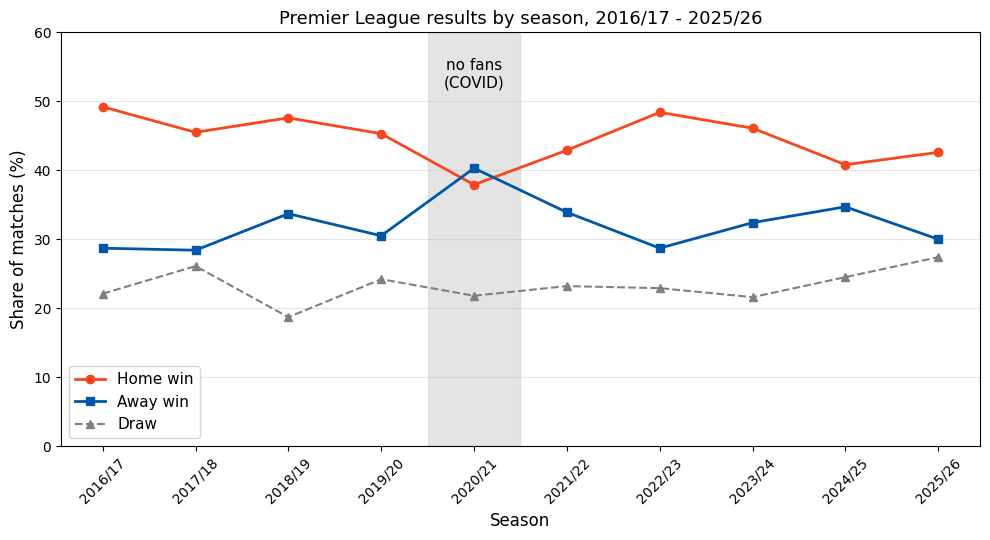

In [4]:
fig, ax = plt.subplots(figsize=(10, 5.5))

x = seasons["season"].to_list()
ax.axvspan(2019.5, 2020.5, color="lightgrey", alpha=0.6)
ax.text(2020, 52, "no fans\n(COVID)", ha="center", fontsize=11)

ax.plot(x, seasons["home_win_pct"], marker="o", color="#f9461c", linewidth=2, label="Home win")
ax.plot(x, seasons["away_win_pct"], marker="s", color="#0057a8", linewidth=2, label="Away win")
ax.plot(x, seasons["draw_pct"], marker="^", color="grey", linewidth=1.5, linestyle="--", label="Draw")

ax.set_xticks(x)
ax.set_xticklabels(seasons["label"].to_list(), rotation=45)
ax.set_ylim(0, 60)
ax.set_xlabel("Season", fontsize=12)
ax.set_ylabel("Share of matches (%)", fontsize=12)
ax.set_title("Premier League results by season, 2016/17 - 2025/26", fontsize=13)
ax.legend(fontsize=11, loc="lower left")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Each point is one full season (380 matches). The grey band is 2020/21, played without fans.

**So what?** In 9 of 10 seasons home teams won more than away teams (home win about 41-49%, away win about 28-35%). 2020/21 is the only season where the lines cross: away teams won 40.3% and home teams 37.9%. Once fans came back home wins went up again (42.9% in 2021/22, 48.4% in 2022/23), which fits the idea that fans are part of home advantage.

**Expected?** Partly. I expected home advantage to shrink without fans, but not to flip. Seasons with fans also move around more than I thought (40.8% in 2024/25 vs 48.4% in 2022/23).

**What next?** 2020/21 was weird in other ways too (packed schedule, no preseason), so this doesn't prove fans cause it; comparing other leagues that played without fans would help. The last 92 matches of 2019/20 were also behind closed doors but are hidden in Nate's season totals. Also, Dominic's and my files have cards and fouls, so I want to check if referees treated home teams differently without fans.

## Anomalies

| anomaly | rows affected | what I did |
|---|---|---|
| `epl_data.csv` 2024 season is only half a season (199 matches instead of 380) | 20 rows | left out, used Youssef's 2024/25 instead |
| season and result are coded differently in each file | all rows | made one `season` column (start year) and changed results to H / D / A |
| 2019/20 has 92 no-fans matches inside the season total | 92 matches | flagged, can't split them with season totals |

I also checked 2020/21 against Dominic's match-by-match `epl_2020.csv` and got the same counts (144 / 83 / 153).

**Revised question:** does home advantage shrink or disappear without fans, and does it come back when they return?